# 07 · Results: splits, thresholds, error sources, models and the embedding-search comparison

Collects notebooks 03–06 and applies the thresholds below. F1 is against the answer key
(reference plans on official maps). Medians are over scored questions (≥ 50 true pixels), with 95% intervals from
resampling questions (2,000 times, seed 0).

Splits: **S1** as written (≤ 1 condition beyond the land class), **S2** the same questions reworded by hand, **S3**
new combinations (≥ 2 conditions), **S4** held-out states (all questions, as written).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from askmap.config import PROJECT_ROOT, load_config
from askmap.score import median_ci, share_ci

cfg = load_config(PROJECT_ROOT / "configs" / "feasibility.yaml")
Q = {q["id"]: q for q in load_config(PROJECT_ROOT / "configs" / "queries.yaml")["queries"]}
RW = load_config(PROJECT_ROOT / "configs" / "reworded.yaml")["reworded"]
RES = PROJECT_ROOT / "outputs" / "results"
FIG = PROJECT_ROOT / "outputs" / "figures"
B, S = cfg["scoring"]["bootstrap"], cfg["scoring"]["seed"]
lm = json.loads((RES / "03_land_maps.json").read_text())
lj = json.loads((RES / "04_land.json").read_text())
land = pd.read_csv(RES / "04_land.csv")
tr = pd.read_csv(RES / "05_translation.csv")
es = pd.read_csv(RES / "06_embedding_search.csv")
ej = json.loads((RES / "06_embedding_search.json").read_text())


def split(df, name):
    d = df[df.scored]
    if name == "S1":
        return d[(d.wording == "as_written") & ~d.heldout & (d.n_extra <= 1)]
    if name == "S2":
        return d[(d.wording == "reworded") & ~d.heldout & (d.n_extra <= 1)]
    if name == "S3":
        return d[(d.wording == "as_written") & ~d.heldout & (d.n_extra >= 2)]
    return d[d.heldout & (d.wording == "as_written")]


def mci(x):
    return median_ci(np.asarray(x, dtype=float), B, S)


land_w = pd.concat([land.assign(wording=w) for w in ("as_written", "reworded")])
main = tr[tr.arm == "main"]

## Thresholds

The printed keys mean:
- `D0`, `K`, `L1`, `L2`, `X1`, `X2`: carried over from notebooks 03 and 04;
- `T1`: translation F1 on S1, median at least 0.90 and at least 80% of questions at 0.90 or more;
- `T2`, `T3`: translation F1 on S2 and S3, median at least 0.85;
- `E1` to `E4`: end-to-end F1 on S1 to S4, median at least 0.55, 0.50, 0.45 and 0.45;
- `C`: end-to-end F1 of the main method minus top-k F1 of the CLIP-style search on S1, lower 95% bound above 0.

In [2]:
V = {
    "D0": {"pass": lj["D0"]["pass"], "median_F1": lj["D0"]["median_F1"]},
    "K": lm["K"],
    "L1": lj["L1"],
    "L2": lj["L2"],
    "X1": lm["X"]["X1"],
    "X2": lm["X"]["X2"],
}
s1 = split(main, "S1")
t1 = mci(s1.F1_translation)
good = share_ci((s1.F1_translation >= 0.90).to_numpy(), B, S)
V["T1"] = {"pass": t1[0] >= 0.90 and good[0] >= 0.80, "median_F1": t1, "share_F1_ge_0.90": good, "n": len(s1)}
for mark, sp, bar in (("T2", "S2", 0.85), ("T3", "S3", 0.85)):
    v = mci(split(main, sp).F1_translation)
    V[mark] = {"pass": v[0] >= bar, "median_F1": v, "n": len(split(main, sp))}
for mark, sp, bar in (("E1", "S1", 0.55), ("E2", "S2", 0.50), ("E3", "S3", 0.45), ("E4", "S4", 0.45)):
    v = mci(split(main, sp).F1_end_to_end)
    V[mark] = {"pass": v[0] >= bar, "median_F1": v, "n": len(split(main, sp))}
clip = es[es.model == "clip"]
pair = split(main, "S1").set_index("id").F1_end_to_end - split(clip, "S1").set_index("id").F1_topk
c = mci(pair.dropna())
valid_clip = bool(ej["planted_pass"] and ej["shuffled_pass"])
V["C"] = {
    "pass": c[1] > 0,
    "median_diff_main_minus_clip": c,
    "n": int(pair.notna().sum()),
    "clip_arm_valid": valid_clip,
}
for k in ("D0", "K", "T1", "T2", "T3", "L1", "L2", "X1", "X2", "E1", "E2", "E3", "E4", "C"):
    print(f"{k}: {'PASS' if V[k]['pass'] else 'FAIL'}", {kk: vv for kk, vv in V[k].items() if kk != "pass"})
print("CLIP arm checks:", {k: v for k, v in ej.items() if k != "minutes"})

D0: FAIL {'median_F1': [0.7765921643933245, 0.6346409799454082, 0.9179598295362595]}
K: PASS {'mean_excess': -0.0010400017384681066, 'seconds': 127}
T1: PASS {'median_F1': (1.0, 1.0, 1.0), 'share_F1_ge_0.90': (0.918918918918919, 0.8108108108108109, 1.0), 'n': 37}
T2: PASS {'median_F1': (1.0, 1.0, 1.0), 'n': 37}
T3: PASS {'median_F1': (1.0, 1.0, 1.0), 'n': 12}
L1: PASS {'median_F1': [0.6311273045832836, 0.47164811870694223, 0.8070633089194341], 'n': 49}
L2: PASS {'median_F1': [0.5613085959991706, 0.4016422856212073, 0.6068841642326152], 'n': 40}
X1: FAIL {'F1': 0.47164811870694223, 'true_px': 6955, 'pred_px': 2480}
X2: FAIL {'F1': 0.3772368567300211, 'true_px': 14414, 'pred_px': 3580}
E1: PASS {'median_F1': (0.6311273045832836, 0.3884241656104774, 0.814501689882967), 'n': 37}
E2: PASS {'median_F1': (0.7184025847061859, 0.47164811870694223, 0.8085099154359902), 'n': 37}
E3: PASS {'median_F1': (0.5032224192209377, 0.12631041817202893, 0.7630456983846794), 'n': 12}
E4: PASS {'median_F1': (

## Where the errors come from (main model): translation vs land maps vs end to end, and the CLIP-style search

In [3]:
rows = []
for sp in ("S1", "S2", "S3", "S4"):
    m, lw = split(main, sp), split(land_w, sp)
    rows.append(
        {
            "split": sp,
            "n": len(m),
            "translation (plan on official maps)": mci(m.F1_translation)[0],
            "land maps (reference plan on AlphaEarth maps)": mci(lw.F1_land)[0],
            "end to end": mci(m.F1_end_to_end)[0],
            "embedding search, top-k F1": mci(split(clip, sp).F1_topk)[0],
            "embedding search, AP": mci(split(clip, sp).AP)[0],
            "chance (median share)": float(
                m.merge(land[["id", "pool", "prevalence"]], on=["id", "pool"]).prevalence.median()
            ),
        }
    )
errors = pd.DataFrame(rows).set_index("split")
V["error_split"] = errors.to_dict()
errors.round(3)

,n,translation (plan on official maps),land maps (reference plan on AlphaEarth maps),end to end,"embedding search, top-k F1","embedding search, AP",chance (median share)
split,,,,,,,
S1,37,1.0,0.721,0.631,0.515,0.478,0.045
S2,37,1.0,0.721,0.718,0.437,0.385,0.045
S3,12,1.0,0.503,0.503,0.238,0.241,0.067
S4,40,1.0,0.561,0.547,0.106,0.099,0.026


## Model comparison

In [4]:
mrows = []
for arm, model in cfg["llm"]["models"].items():
    a = tr[tr.arm == arm]
    for sp in ("S1", "S2", "S3", "S4"):
        d = split(a, sp)
        row = {
            "arm": arm,
            "model": model,
            "split": sp,
            "n": len(d),
            "malformed": int(d.error.notna().sum()),
            "exact_plan": float(d.exact.mean()),
            "translation_median": mci(d.F1_translation),
            "end_to_end_median": mci(d.F1_end_to_end),
        }
        if arm != "main":
            x = (
                d.set_index(["id", "pool"]).F1_translation
                - split(main, sp).set_index(["id", "pool"]).F1_translation
            )
            row["translation_diff_vs_main"] = mci(x.dropna())
        mrows.append(row)
models = pd.DataFrame(mrows)
V["models"] = models.to_dict("records")
models.assign(
    **{
        c: models[c].map(lambda v: tuple(round(x, 3) for x in v) if isinstance(v, tuple) else v)
        for c in ("translation_median", "end_to_end_median", "translation_diff_vs_main")
    }
)

,arm,model,split,n,malformed,exact_plan,translation_median,end_to_end_median,translation_diff_vs_main
0,main,openai/gpt-oss-120b:groq,S1,37,2,0.837838,"(1.0, 1.0, 1.0)","(0.631, 0.388, 0.815)",NaN
1,main,openai/gpt-oss-120b:groq,S2,37,1,0.810811,"(1.0, 1.0, 1.0)","(0.718, 0.472, 0.809)",NaN
2,main,openai/gpt-oss-120b:groq,S3,12,0,0.833333,"(1.0, 1.0, 1.0)","(0.503, 0.126, 0.763)",NaN
3,main,openai/gpt-oss-120b:groq,S4,40,1,0.825000,"(1.0, 1.0, 1.0)","(0.547, 0.364, 0.602)",NaN
4,large,zai-org/GLM-5.3:nscale,S1,37,2,0.864865,"(1.0, 1.0, 1.0)","(0.631, 0.472, 0.815)","(0.0, 0.0, 0.0)"
5,large,zai-org/GLM-5.3:nscale,S2,37,2,0.864865,"(1.0, 1.0, 1.0)","(0.603, 0.42, 0.815)","(0.0, 0.0, 0.0)"
6,large,zai-org/GLM-5.3:nscale,S3,12,0,1.000000,"(1.0, 1.0, 1.0)","(0.503, 0.126, 0.763)","(0.0, 0.0, 0.0)"
7,large,zai-org/GLM-5.3:nscale,S4,40,1,0.900000,"(1.0, 1.0, 1.0)","(0.547, 0.364, 0.602)","(0.0, 0.0, 0.0)"
8,small,openai/gpt-oss-20b:groq,S1,37,2,0.810811,"(1.0, 1.0, 1.0)","(0.603, 0.388, 0.814)","(0.0, 0.0, 0.0)"
9,small,openai/gpt-oss-20b:groq,S2,37,0,0.810811,"(1.0, 1.0, 1.0)","(0.518, 0.388, 0.808)","(0.0, 0.0, 0.0)"


## Every question in S1–S4 (main model)

In [5]:
tab = main[main.scored].merge(
    land[["id", "pool", "F1_land", "prevalence", "AP_like_point"]], on=["id", "pool"]
)
tab = tab.merge(
    clip[["id", "wording", "pool", "F1_topk"]].rename(columns={"F1_topk": "F1_embedding_search"}),
    on=["id", "wording", "pool"],
)
tab["question"] = [
    Q[i]["question"] if w == "as_written" else RW[i] for i, w in zip(tab.id, tab.wording, strict=True)
]
pd.set_option("display.max_colwidth", 120)
cols = [
    "id",
    "wording",
    "pool",
    "F1_translation",
    "F1_land",
    "F1_end_to_end",
    "F1_embedding_search",
    "prevalence",
    "error",
    "question",
]
tab.sort_values(["wording", "pool", "F1_end_to_end"])[cols].round(3)

,id,wording,pool,F1_translation,F1_land,F1_end_to_end,F1_embedding_search,prevalence,error,question
102,nc07,as_written,georgia,1.0,0.085,0.085,0.049,0.001,NaN,"In the North Carolina study area, show solar farms within 100 m of forest."
93,nc04,as_written,georgia,1.0,0.092,0.092,0.000,0.000,NaN,"In the North Carolina study area, show patches of grassland and pasture of at least 10 ha within 2 km of an existing..."
110,nc14,as_written,georgia,1.0,0.146,0.146,0.137,0.000,NaN,"In the North Carolina study area, show soybean fields where September 2024 rainfall was in the wettest 10% of Septem..."
119,nc18,as_written,georgia,1.0,0.259,0.259,0.007,0.003,NaN,"In the North Carolina study area, show wetlands within 500 m of an existing solar farm."
90,nc03,as_written,georgia,1.0,0.329,0.329,0.110,0.026,NaN,"In the North Carolina study area, show grassland and pasture within 2 km of an existing solar farm."
...,...,...,...,...,...,...,...,...,...,...
22,nd09,reworded,north_dakota,1.0,0.921,0.921,0.822,0.428,NaN,"In hectares, how much North Dakota cropland received 250 mm of rain or more between April and June 2022?"
45,nd20,reworded,north_dakota,1.0,0.921,0.921,0.909,0.428,NaN,How much North Dakota cropland (hectares) had a May-September 2021 average temperature in the hottest 10% of 2001-2025?
37,nd17,reworded,north_dakota,1.0,0.924,0.924,0.827,0.127,NaN,Corn in the North Dakota area that saw at least five days over 35 C in July 2021.
18,nd07,reworded,north_dakota,1.0,0.926,0.926,0.627,0.323,NaN,Which North Dakota crop fields had one of the 10% wettest April-to-June periods of 2001-2025 in 2022?


## By persona (main model, S1 and S2, end to end)

In [6]:
pd.concat([split(main, s).assign(split=s) for s in ("S1", "S2")]).groupby(["split", "persona"]).agg(
    n=("id", "size"), translation=("F1_translation", "median"), end_to_end=("F1_end_to_end", "median")
).round(3)

n  translation  end_to_end
split persona                                 
S1    fsa_lfp       3          1.0       0.831
      fsa_pp        4          1.0       0.924
      nrcs          9          1.0       0.234
      power_ag      3          1.0       0.918
      power_build   3          0.0       0.000
      power_energy  9          1.0       0.472
      rma           6          1.0       0.873
S2    fsa_lfp       3          1.0       0.831
      fsa_pp        4          1.0       0.820
      nrcs          9          1.0       0.234
      power_ag      3          1.0       0.918
      power_build   3          1.0       0.740
      power_energy  9          1.0       0.472
      rma           6          1.0       0.873

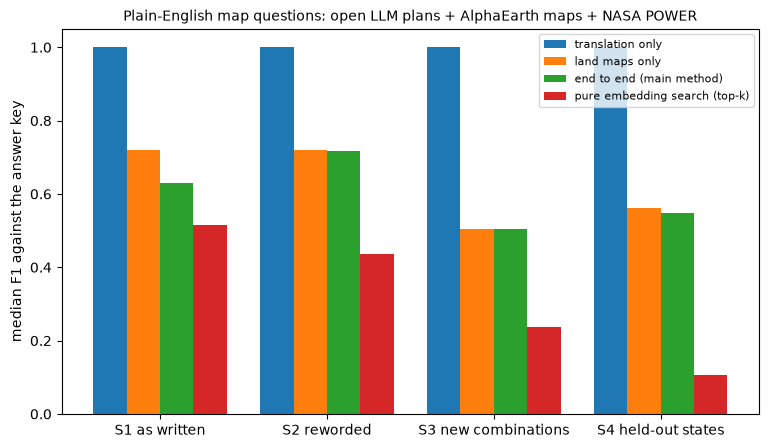

In [7]:
(RES / "07_verdicts.json").write_text(json.dumps(V, indent=1, default=str))
fig, ax = plt.subplots(figsize=(9, 5))
for k, (col, lab) in enumerate(
    [
        ("translation (plan on official maps)", "translation only"),
        ("land maps (reference plan on AlphaEarth maps)", "land maps only"),
        ("end to end", "end to end (main method)"),
        ("embedding search, top-k F1", "pure embedding search (top-k)"),
    ]
):
    ax.bar(np.arange(4) + 0.2 * (k - 1.5), errors[col], width=0.2, label=lab)
ax.set_xticks(range(4), ["S1 as written", "S2 reworded", "S3 new combinations", "S4 held-out states"])
ax.set_ylabel("median F1 against the answer key")
ax.legend(fontsize=8)
ax.set_title("Plain-English map questions: open LLM plans + AlphaEarth maps + NASA POWER", fontsize=10)
fig.savefig(FIG / "07_error_split.png", dpi=110)
plt.show()